# N155: Does memory allocation offer useful, predictable health control?

Designed 5 November; implementation/run authorized 6 November 2026. Expanded
before launch to include a matched clip-order control after checking the source
stream's constructed day/night pattern. A background Python worker updates the
notebook and HTML report; no notebook kernel needs to remain open.

## Motivation and hypothesis

N150 established recent replay as a strong fixed baseline. N151-N153 did not
improve on it by controlling learning rate/action with H1 health objectives.
N154 found small constrained oracle gains in its matched-dose plan library;
paired RankMe-advantage prediction lost to zero advantage in all six held-out
stream/horizon comparisons. Longer planning alone is therefore not the next test.

Test whether allocating replay between recent and older experience creates a
larger, persistent health benefit, and whether that benefit depends predictably on
the current health state. Separate a better fixed replay policy from evidence for
state-dependent planning. Longer streams give memory competition time to develop;
they do not guarantee that it will develop.

## Data, duration, and repetitions

- Three disjoint development streams of 192 clips / 18,432 arrivals each.
  Preserve within-clip order and freeze a deterministic manifest before training.
  Take the first 576 eligible clips in inherited catalog order, excluding exact
  pixel collisions with offline/fixed-audit images or previously selected frames.
  Record every such exclusion; no health outcome determines selection.
  Validate availability, hashes, and separation between streams. Use previously used reserved development clips;
  do not describe recombination as fresh data or consume the final ten unused
  clips. No stream or ordering may be selected using prior policy outcomes.
- Two training/replay RNG seeds per stream, sharing the original full model/Adam
  parent. Pair each seed across all methods. These are seed repetitions, not six
  independent data streams or different pretrained initializations.
- Two orderings: inherited structured day/night order, and a deterministic
  permutation of interior clips 11..188. Preserve the first 11 and last 3 clips
  so initial-context/audit and future-tail identities match exactly. Frames stay
  chronological inside each clip. This is an interior clip-order control, not
  globally shuffled frames. Both orders contain precisely the same images. The
  initial 32 and final 32 training arrivals consequently also share their order.
- First 1,024 arrivals build causal memory, without updates. Select 128 of those
  arrivals as an independent initial audit, excluded from all replay and control
  banks. Reserve the last 256 arrivals for final-only future evaluation.
- Train at every arrival with index 1,024 through 18,175 inclusive: 17,152 Adam
  steps, five gradient-image presentations each, or 85,760 per trajectory.
- Three policies x three streams x two seeds x two orderings = 36 sustained trajectories,
  617,472 updates / 3,087,360 gradient-image presentations. Evaluation and paired
  diagnostics are additional work and must be reported separately.

## Fixed policies and memory

All arms use nominal LR 1e-4 times 1/4, the existing optimizer/clipping settings,
and loss .5 current-view reconstruction + .5 mean reconstruction of four replay
images. No holds, reduced-rate actions, or extra optimizer steps.

Maintain the same memory in every arm: a recent FIFO of 256 eligible images and a
uniform reservoir of capacity 2,048 fed by eligible images when they leave that
FIFO. Audit images never enter either store. The stores are disjoint and updated
causally; the current image enters only after its update. All arms have equal
memory capacity and storage overhead, even when their policy ignores one store.

Policies:

1. Recent: four uniformly sampled recent images, reproducing the recent-replay
   baseline's policy under the new shared stream/assay protocol.
2. Mixed: two recent and two older reservoir images.
3. Older: four older reservoir images.

Sample without replacement within an update. Share current-view augmentation and
deterministic replay sampling substreams where applicable. Record the actual ages
and identities of replay samples; different stores need not yield identical IDs.

## Health observations

Record actual incoming reconstruction loss before and after every update, plus
embedding norm and pre/post embedding cosine. RankMe is a population statistic,
so do not label it as a meaningful single-image RankMe measurement.

Every 128 updates, freshly evaluate reconstruction loss and RankMe on the recent
256 images and a deterministic 256-image panel from the older reservoir. Save
identities, individual losses, and current embeddings. Separate bank replacement
from model-update effects when comparing changing banks. Use identity-fixed
reconstruction masks; compare RankMe within matched panels, not raw levels between
different populations. Re-evaluate the preceding panel under the current model
to separate learning over the observation interval from bank replacement; no
stale embeddings are used as current targets. Every 512 updates (and at the
start/end), evaluate the independent initial audit and existing fixed older
audit. Neither may feed the predictor or action selector. Evaluate
the 256-image future tail only after training, without updating on it.

Report full health trajectories, stream/seed paired differences, mean incoming
pre-update loss, and final audit results. Recent/older control banks can overlap
training replay and are not independent generalization tests. No task probes/kNN
are required. Report optimization, observation, and diagnostic costs separately.

## Paired plan identification

Along each recent-policy reference trajectory, preselect 12 origins, balanced
across time using 12 equally spaced bins of eligible 128-step observation points,
with room for 96 subsequent updates and no selection on future outcomes. Both
orders use the same origin indices. This gives 144 origins and 1,296 plans.
Stratify results afterward
using only health deterioration signals available before each origin; do not
use future scene labels or oracle outcomes to define the strata.

At every origin, restore identical full NN/Adam/mode/RNG state for each branch.
Enumerate the nine ordered two-block plans over {Recent, Mixed, Older}. Each block
lasts 16 updates. Each plan therefore has 32 steps, 160 gradient presentations,
and the same LR dose. Follow every plan with 64 updates of the common Recent
policy to test persistence at H96. Branches see the actual arrivals only as they
arrive; future arrivals are label-generation data, never prediction inputs.

Freeze both 256-image control-panel memberships and assay masks at the origin for
all H16/H32/H96 measurements. Recompute their losses and embeddings under each
branch model. Memory stores themselves continue evolving causally. Audit the
independent initial and fixed older panels at H32/H96, outside selection.

Share identical first-block states across their three second-block branches.
Work is 3*16 + 9*16 + 9*64 = 768 unique diagnostic steps per origin, or 110,592
steps / 552,960 gradient presentations total. Diagnostics restore the reference
state and never alter the sustained reference trajectory or count as online
learning by its deployed policy.

Predict paired advantages against Recent->Recent for mean incoming pre-update
loss and terminal recent/older reconstruction loss and RankMe at H32 and H96.
Positive advantage always favors the candidate. Log unnormalized values and
normalizations based only on origin measurements.

## Predictor qualification and objective

Use a fixed small ridge model per plan, retaining N154's implementation choices
where applicable. The 31 frozen features are: log current loss/norm; RGB means
and standard deviations; for each bank log loss/RankMe/embedding norm and log
loss quantiles 10/50/90 plus current-to-mean-embedding cosine; four relative
learning deltas on the preceding fixed panels; log1p Adam moment norms; log1p
recent mean age, older mean age, and older age q90. No model/hyperparameter sweep.

Qualify separately within each ordering. Leave one entire physical stream out,
keeping both seeds and all branches from an origin together. The alternative
ordering of a held-out stream never enters its fitting/calibration data. Fit
scaling, heads, and empirical one-sided error margins only inside
the training streams, with inner stream-held-out calibration. No test outcome
chooses objectives, margins, features, or a fixed comparator. Treat three streams
as limited descriptive evidence, not hundreds of independent branch replications.

Primary selection minimizes predicted mean incoming loss at H32 subject to no
predicted relative deterioration in recent/older bank loss and RankMe at both H32
and H96. Use zero tolerance for the prespecified primary descriptive comparison,
and show the full measured tradeoff frontier rather than tuning a permissive rank
floor until a policy wins. RankMe is a guard, not an additive reward. Calibrated
selection subtracts training-only overprediction margins and defaults to Recent.
These empirical margins do not provide a joint safety guarantee.

Compare raw and calibrated selectors with Recent->Recent, the best fixed
composition chosen from training streams, the best fixed two-block schedule chosen
from training streams, uniform-plan expected performance, a measured guarded
oracle, and an unconstrained incoming-loss oracle. A better fixed schedule is not
evidence that observing state is useful. Report advantage, harmful-switch rate,
constraint violations, oracle regret, and paired RMSE relative to zero advantage.
Check whether rankings and health gains persist at H96 and on independent audits.

The SSL learner trains online. This paired-advantage qualification predictor is
fitted offline with grouped evaluation. A future online MPC cannot obtain the
unexecuted baseline advantage for free: its learning design must use valid
chosen-action outcome feedback or explicitly budget paired diagnostic trials.

## Interpretation and next decision

- One fixed composition wins: adopt/test that stronger fixed baseline; do not
  attribute its gain to MPC.
- Conditional plans have substantial persistent oracle gains, but learned
  selection fails: improve action-relevant state/prediction before deployment.
- Held-out selection beats Recent and training-selected fixed comparators,
  respects measured health constraints, and survives continuation/audits across
  streams and seeds: justify a separate receding-horizon deployment experiment,
  executing 16 updates then replanning, on fresh data.
- Gains occur only with retention/adaptation tradeoffs: report the frontier and
  choose an explicit acceptable tradeoff before designing a deployment objective.
- No meaningful oracle opportunity: stop pursuing this memory-composition menu;
  neither a larger predictor nor a longer planner is justified by these results.

Report absolute and relative effect sizes. As a prespecified practical reference,
highlight whether incoming-loss gains reach 0.1% relative to the comparator;
this is a research target, not a statistically derived health/safety threshold.
Do not call a microscopic positive effect a deployment justification. The result
remains development evidence until independently evaluated on fresh streams.


# N155 — Replay memory, stream order, and health-centered MPC

> Rebuilt from saved experiment state. The older-replay trajectory plots use the latest readable checkpoint at 10,496 arrivals. The archived report recorded 10,752 arrivals.

Status: **sustained**; updated 2026-11-06T00:21:00.559493+00:00.

Sustained trajectories: 2/36 complete. Paired outcomes: 108/1296; complete origins: 12/144.

Active: stream_a__structured__155101, older, arrivals 10496/18176.

Three 18,432-image development streams; two seeds; structured and shuffled clip orders; recent/mixed/older replay. The representation learner trains online. Paired advantage prediction is qualified offline after all data collection; no MPC is deployed.

Every arm uses quarter LR, one current image plus four replay images, and 17,152 optimizer steps. Shuffling keeps the same first 11 and last 3 clips; interior frames remain chronological. Health panels are sampled from causal memory. Independent initial/fixed audits and the future tail never guide selection.

## Trajectories

| Stream / order / seed | Policy | Received training-context images | Updates | Mean incoming pre-loss | Final future loss |
|---|---|---:|---:|---:|---:|
| stream_a__structured__155101 | mixed | 18176 | 17152 | 0.7735408999898068 | 0.7427580785006285 |
| stream_a__structured__155101 | older | 10496 | 9472 | 0.7608222134656751 | — |
| stream_a__structured__155101 | recent | 18176 | 17152 | 0.7814852612635205 | 0.7407404490513727 |

Partial trajectories are progress displays; compare effects only on matched completed runs. Bank membership changes are logged separately from learning on the preceding fixed panel.

Accumulated measured wall seconds (checkpoint/report overhead additional): {'training': 1448.0844759927131, 'incoming_measurement': 832.4441461011302, 'health': 110.38567200035322, 'audits': 8.180435000103898, 'diagnostics': 554.493715499877}.

## Completed paired sustained comparisons

Positive advantage favors the alternative over recent replay. Vector: incoming loss; recent loss/RankMe; older loss/RankMe; independent initial loss/RankMe; fixed older loss/RankMe; future loss/RankMe.

## Paired planning diagnosis

Target order: incoming32, recent_loss32, recent_rank32, older_loss32, older_rank32, incoming96, recent_loss96, recent_rank96, older_loss96, older_rank96. Positive advantages favor the candidate. Both recent and older loss/RankMe must satisfy the primary zero-tolerance guard at H32 and H96.

stream_a__structured: 12/24 origins; measured guarded-oracle switches 0.

Past-only stratum older_loss_rising: 7 origins; guarded-oracle mean incoming H32 advantage +0.0000000.

Past-only stratum older_loss_not_rising: 5 origins; guarded-oracle mean incoming H32 advantage +0.0000000.

Held-out predictor qualification waits for all 36 trajectories and all 144 verified origins. Oracle results are descriptive upper bounds, not deployable policies.

Qualification is separate within each ordering, holding out the physical stream and both its seeds together. Order variants are not independent streams. No automatic MPC deployment follows this experiment.


### Actual incoming-image reconstruction and health
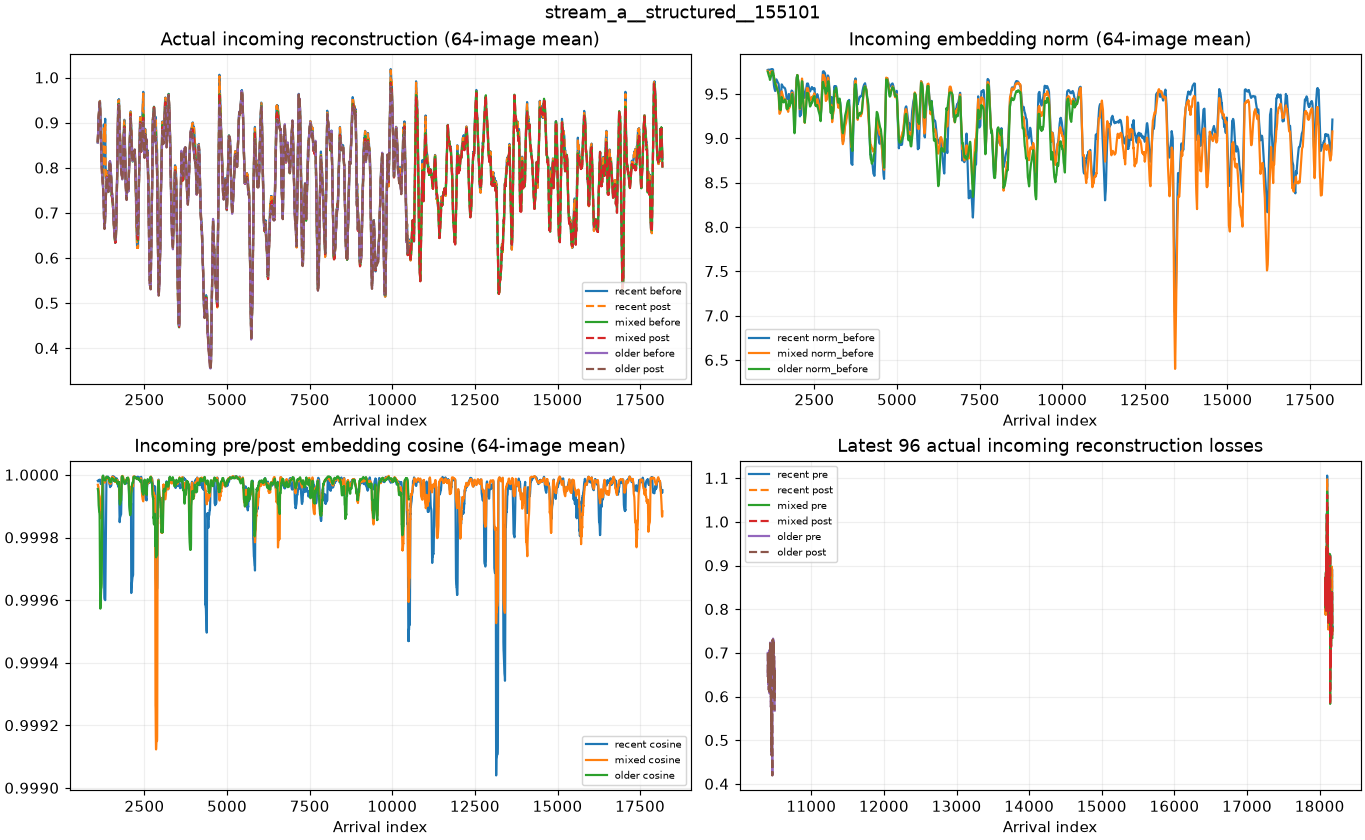

### Recent and older memory health
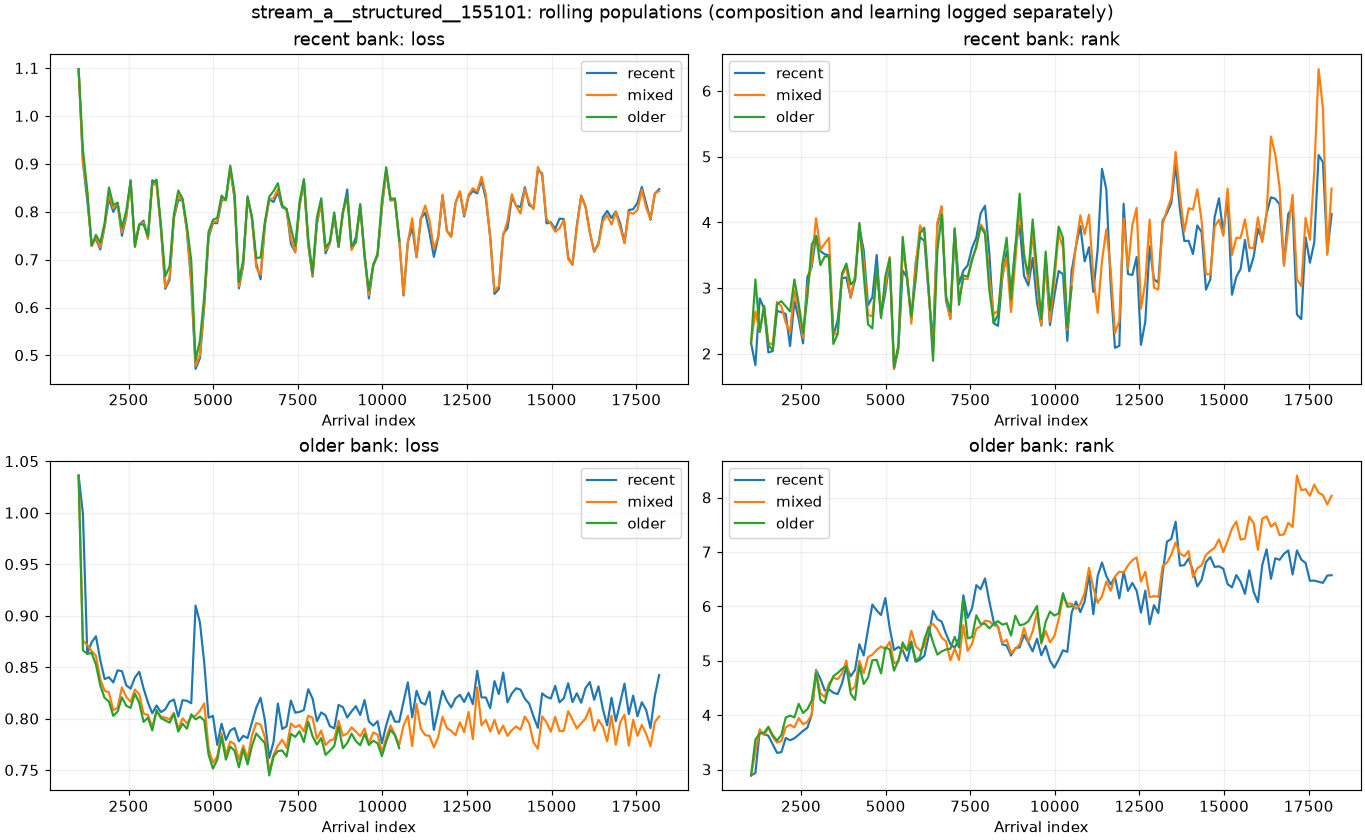

### Independent health audits excluded from control and replay
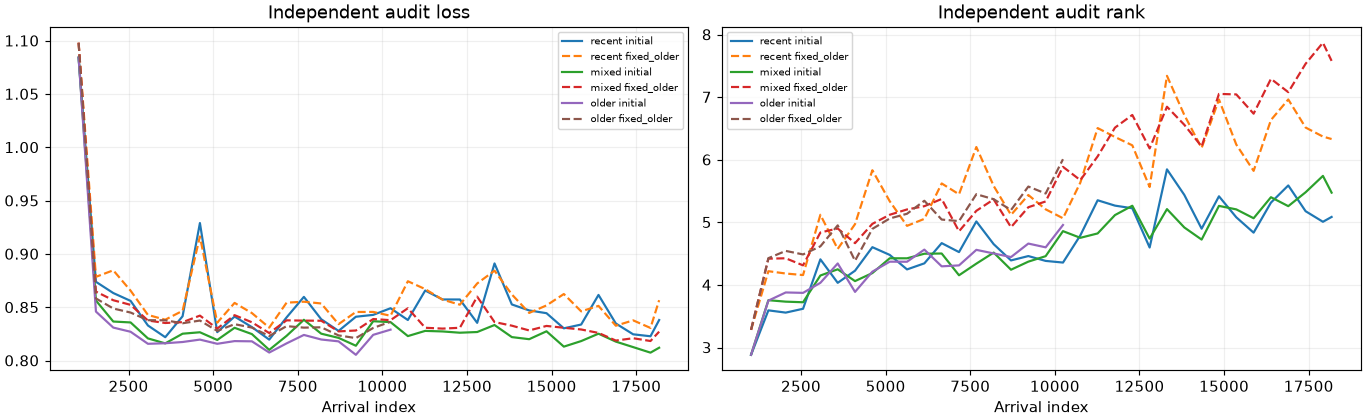

### Measured H32 incoming-loss advantages of replay-composition plans
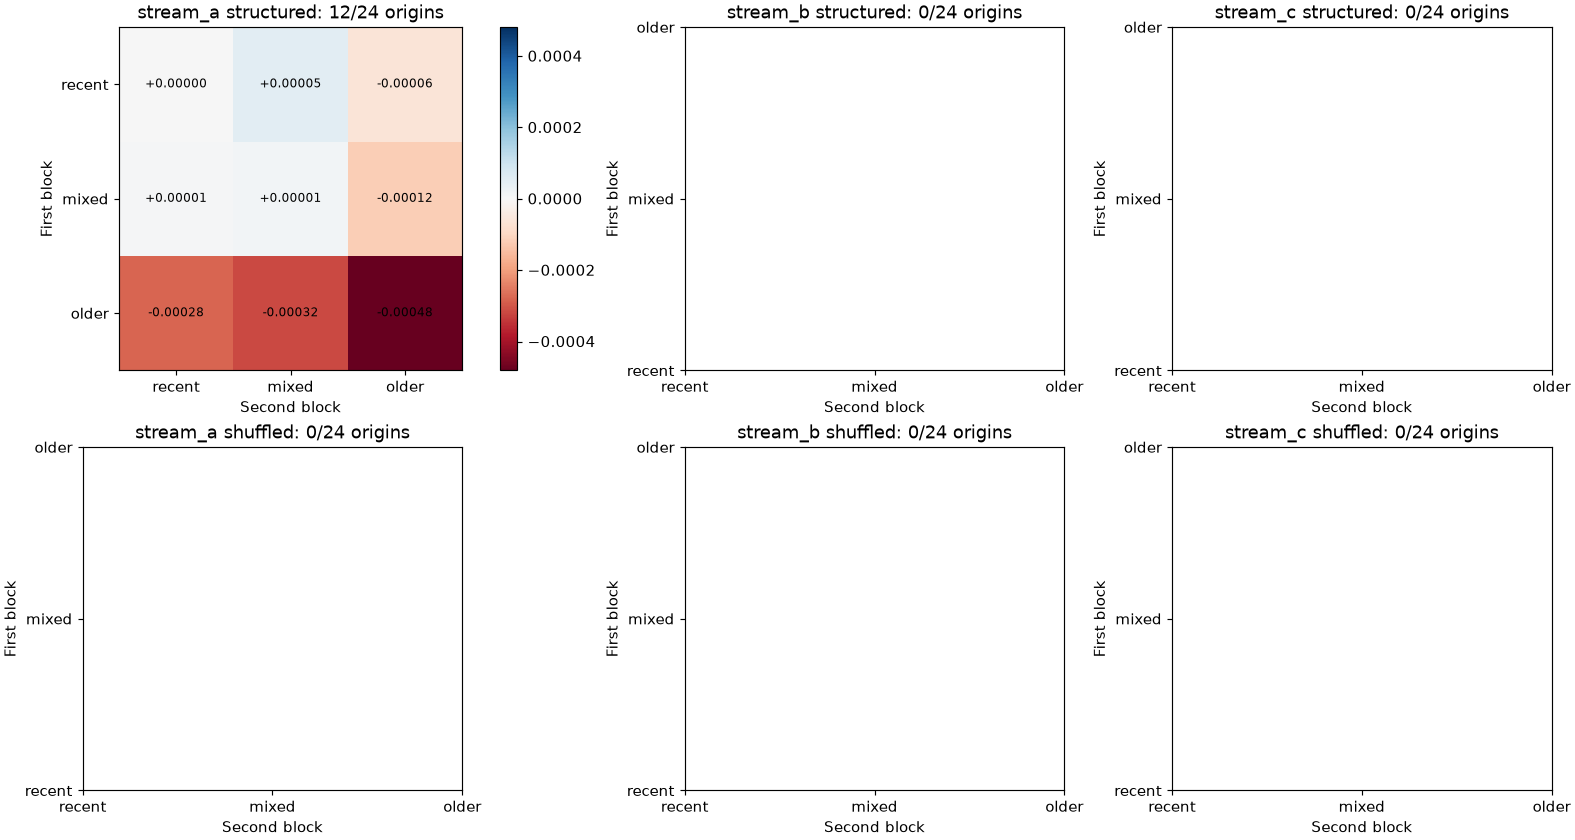

### Incoming reconstruction across both orderings, all streams, and both seeds
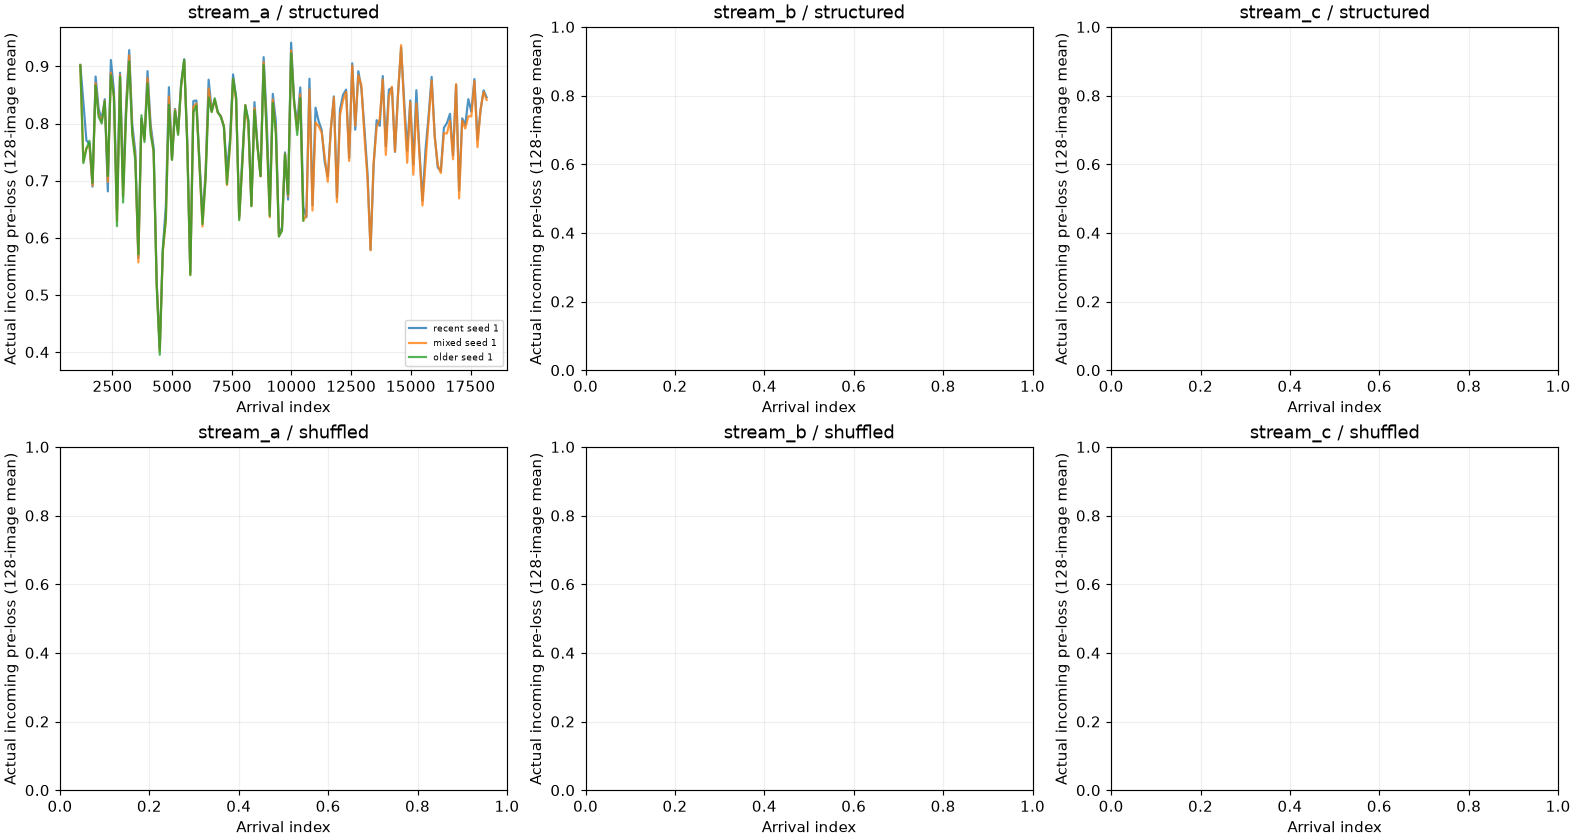